In [1]:
from os import chdir
from os.path import abspath
thepath = abspath("../base")
chdir(thepath)

# yaml processing file loading. 
import yaml
import numpy as np
import matplotlib.pyplot as plt

from stl import mesh

# for the maximum spanning tree clearance method
from iterative_section_minimiser import mesh_intersect
from geometry import to2D

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [131]:
with open("../temp/0_rescaling.txt", "r") as f:
    data = f.readlines()

    f.close()

In [132]:
keys = [elem.strip("\n") for c,elem in enumerate(data) if c % 5 == 0]
datalines = [elem.strip("\n").strip(" ").strip("R").strip("(STL units)").strip("=").strip(" ").strip("[]").strip(" ").split() for c, elem in enumerate(data) if c%5 !=0]
numeric_data = np.array([[float(elem1) for elem1 in elem] for elem in datalines])

In [133]:
keys

['8-archamps',
 '10-faux_monnayeurs',
 '11-predjamski',
 '9-motiers',
 '12-lauiloch',
 '1-straight_cyl',
 '3-wavy',
 '4-rough',
 '2-straight_elp',
 '5-sinu_1',
 '6-sinu_2',
 '7-branching']

In [134]:
transformations = {}
for c, key in enumerate(keys):
    print(key.split("-")[-1])
    transformations[key.split("-")[-1]] = {"R": numeric_data[c*4:c*4+3], "t": numeric_data[4*c+3]}

archamps
faux_monnayeurs
predjamski
motiers
lauiloch
straight_cyl
wavy
rough
straight_elp
sinu_1
sinu_2
branching


In [135]:
transformations

{'archamps': {'R': array([[ 9.99999994e-01,  1.09907400e-04,  3.64020000e-06],
         [-1.09907400e-04,  9.99999994e-01, -2.00000000e-10],
         [-3.64020000e-06, -2.00000000e-10,  1.00000000e+00]]),
  't': array([ -56.7357345 ,  -97.08053111, -107.04573177])},
 'faux_monnayeurs': {'R': array([[-2.06202800e-04,  1.85147000e-05, -9.99999979e-01],
         [-1.85147000e-05,  1.00000000e+00,  1.85185000e-05],
         [ 9.99999979e-01,  1.85185000e-05, -2.06202400e-04]]),
  't': array([-0.00479226,  0.33717954, -1.45723727])},
 'predjamski': {'R': array([[-0.7193398 ,  0.69465837,  0.        ],
         [-0.69465837, -0.7193398 ,  0.        ],
         [ 0.        , -0.        ,  1.        ]]),
  't': array([3794.        , 8658.5288411 ,  -84.03320887])},
 'motiers': {'R': array([[ 1.000e+00,  4.183e-07, -9.756e-07],
         [-4.183e-07,  1.000e+00,  0.000e+00],
         [ 9.756e-07,  0.000e+00,  1.000e+00]]),
  't': array([ 15.70029404,   4.48549248, -30.15639775])},
 'lauiloch': {

In [136]:
with open(f"../notebooks/conduit_map.yaml", "r") as f: 
    conduit_map = yaml.safe_load(f)
    f.close()

In [137]:
conduit_map

{1: 'straight_cyl',
 2: 'straight_elp',
 3: 'wavy',
 4: 'rough',
 5: 'sinu_1',
 6: 'sinu_2',
 7: 'branching',
 8: 'archamps',
 9: 'motiers',
 10: 'faux_monnayeurs',
 11: 'predjamski',
 12: 'lauiloch'}

In [138]:
# massive pyvista figure with all the meshes. 

# list all meshes. 
list_meshes = []
list_meshes_fp = []
for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    mesh_fp = f"../data/{conduit_id}_{conduit_name}/{conduit_name}.stl"
    list_meshes.append(mesh.Mesh.from_file(mesh_fp))
    list_meshes_fp.append(mesh_fp)

In [139]:
## plot the hydraulic centrelines. 
list_hydraulic_ct = []

for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    hydraulic_uniform_ct_fp = f"../temp/{conduit_id}_{conduit_name}/hydraulic/hydraulic_uniform.csv"
    hydraulic_flux_ct_fp = f"../temp/{conduit_id}_{conduit_name}/hydraulic/hydraulic_flux.csv"
    
    
    hydraulic_ct1 = np.loadtxt(hydraulic_uniform_ct_fp, skiprows =1, delimiter=",", usecols=[4,5,6])
    hydraulic_ct2 = np.loadtxt(hydraulic_flux_ct_fp, skiprows =1, delimiter=",", usecols=[4,5,6])

    P1 = hydraulic_ct1[0]
    P2 = hydraulic_ct1[-1]

    list_hydraulic_ct.append((hydraulic_ct1, P1, P2, hydraulic_ct2))

In [140]:
conduit_ID = 8

In [141]:
conduit_map[conduit_ID]

'archamps'

In [142]:
themesh = list_meshes[conduit_ID-1] 

In [143]:
ct = list_hydraulic_ct[conduit_ID-1][3]

ct_uniform = list_hydraulic_ct[conduit_ID-1][0]


In [144]:
R = transformations[conduit_map[conduit_ID]]["R"]
t = transformations[conduit_map[conduit_ID]]["t"]

In [145]:
ct_tr = (np.linalg.inv(R) @ (ct + t ).T ).T 
ct_uniform_tr = (np.linalg.inv(R) @ (ct_uniform + t ).T ).T 

In [146]:
t_diff = np.mean(ct_tr, axis = 0)
print(t_diff)

[20.82753511 -2.43864139 -2.95262675]


In [147]:
# columns 1 and 2 switched. 
#ct_tr[:, 2]*=-1
#ct_uniform_tr[:, 2]*=-1

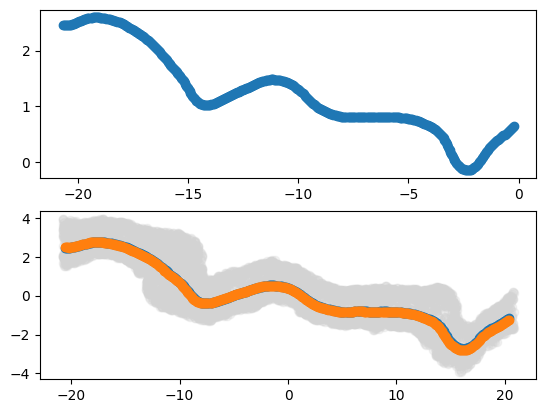

In [149]:
fig, axes = plt.subplots(2, 1) 
ax0, ax1 = axes
#ax0.scatter(*ct[:, [0, 1]].T)
ax0.scatter(*(ct_tr*0.5-t_diff)[:, [0, 1]].T)
#ax0.scatter(*(ct_uniform_tr-t_diff)[:, [0, 1]].T)

ax1.scatter(*themesh.centroids[::100, [0, 1]].T, zorder = -10, color = "lightgrey", alpha = 0.25)
ax1.scatter(*(ct_tr-t_diff + np.array([0,0,-1]))[:, [0, 1]].T)
ax1.scatter(*(ct_uniform_tr-t_diff + np.array([0,0,-1]))[:, [0, 1]].T)



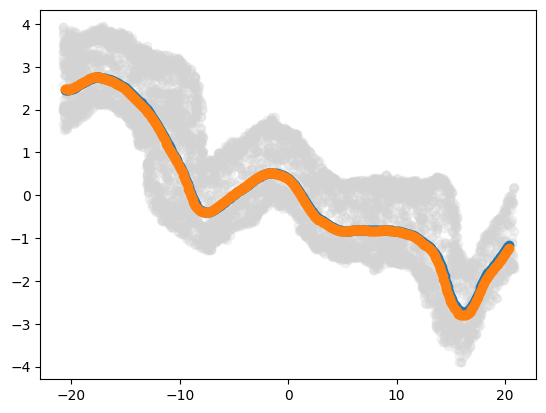

In [150]:
fig, ax = plt.subplots() 

#ax.scatter(*ct[:, [0, 2]].T)
ax.scatter(*(ct_tr-t_diff+ np.array((0,0,-1)))[:, [0, 1]].T)
ax.scatter(*(ct_uniform_tr-t_diff+ np.array((0,0,-1)))[:, [0, 1]].T)

ax.scatter(*themesh.centroids[::100, [0, 1]].T, zorder = -10, alpha = 0.25, color ="lightgrey")

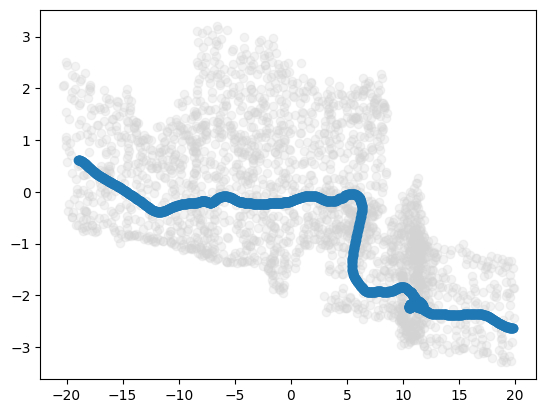

In [127]:
fig, ax = plt.subplots() 

#ax.scatter(*ct[:, [1, 2]].T)
#ax.scatter(*(ct_tr-t_diff)[:, [1, 2]].T)
ax.scatter(*(ct_tr*0.05-t_diff*0.05+ np.array((0,2,-1)))[:, [1, 2]].T)
ax.scatter(*themesh.centroids[::100, [1, 2]].T, zorder = -10, color ="lightgrey", alpha = 0.25)

In [151]:
# switch columns 1 and 2, then scale by 0.2, then add tdiff then final correction.

ct_uniform_new = ct_uniform_tr.copy()-t_diff+ np.array((0,0,-1))
ct_flux_new = ct_tr.copy()-t_diff+ np.array((0,0,-1))

In [152]:
np.savetxt(f"../temp/{conduit_ID}_{conduit_map[conduit_ID]}/hydraulic/uniform_rescaled.csv", ct_uniform_new)
np.savetxt(f"../temp/{conduit_ID}_{conduit_map[conduit_ID]}/hydraulic/flux_rescaled.csv", ct_flux_new)